In [18]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

In [74]:
def UCS(graph,start,goal):
  priority_queue = [(0,start)]
  visited = {start: (0,None)}

  while priority_queue:
        current_cost,current_node = heapq.heappop(priority_queue)

        if current_node == goal:
          return current_cost, reconstruct(visited,start,goal)

        for neighbor, cost in graph[current_node]:
          total_cost = current_cost + cost

          if neighbor not in visited or total_cost < visited[neighbor][0]:
            visited[neighbor] = (total_cost,current_node)
            heapq.heappush(priority_queue,(total_cost,neighbor))


In [75]:
def reconstruct(visited,start,goal):
  path = []
  current = goal

  while current is not None:
    path.append(current)
    current = visited[current][1]
  path.reverse()
  return path

In [76]:
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 1)],
    'C': [('F', 5)],
    'D': [('G', 2)],
    'E': [('G', 1)],
    'F': [('G', 2)],
    'G': []
}


start_node ='A'
goal_node = 'G'


In [77]:
result = UCS(graph,start_node,goal_node)



In [78]:
if result:
  total_cost,path = result
  print(f"Least cost path from {start_node} to {goal_node}: {' -> '.join(path)} with total cost: {total_cost}")

else:
  print(f"No path found")

Least cost path from A to G: A -> B -> D -> G with total cost: 4


In [97]:
def visualize_graph(graph, path=None):
    G = nx.DiGraph()

    # Adding nodes and edges to the graph
    for node, edges in graph.items():
        for neighbor, cost in edges:
            G.add_edge(node, neighbor, weight=cost)

    pos = nx.spring_layout(G)  # Positioning the nodes

    # Drawing the graph
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', node_size=2000, font_size=15, font_weight='bold', edge_color='black')
    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)

    if path:
        # Highlight the path in red
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=1.5)

    plt.title("Uniform Cost Search Path Visualization")
    plt.show()

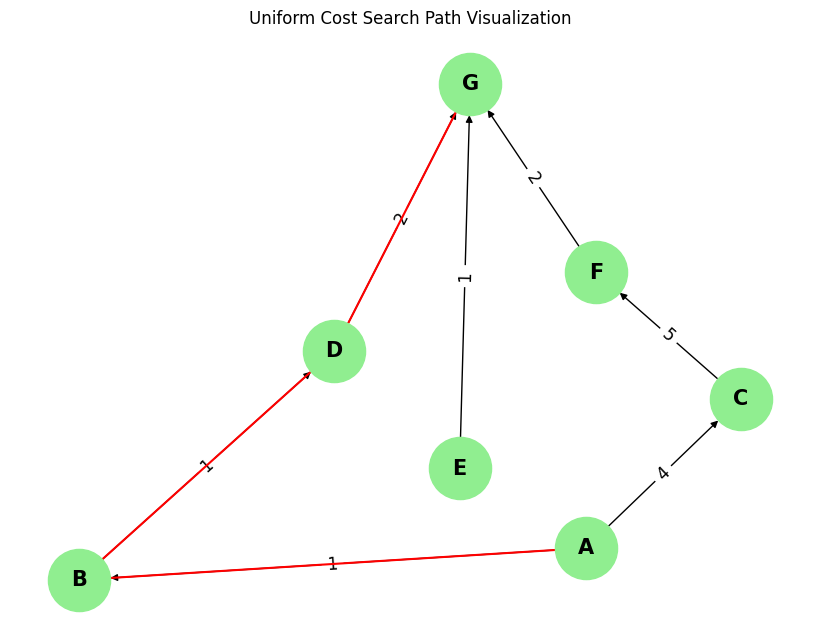

In [98]:
visualize_graph(graph,path)